# 01 · Préparation des données : catalogue de livres (Book Depository)

**Projet NLP : Semantic Analysis and Intelligent Contextual Recommendation Systems (thème 3 : recommandation de livres)**
**Partie : personne 1, Data Engineering**

## Objectif de ce notebook

Transformer le dataset brut **Book Depository** (Kaggle `sp1thas/book-depository-dataset`, ≈ 1,1 million de lignes, 1,1 Go)
en un **catalogue de référence propre** d'environ **12 000 livres** qui alimente tout le reste du projet :

| Sortie | Rôle |
|---|---|
| `data/processed/books_clean.parquet` | catalogue final : entrée de l'enrichissement (P2) et des embeddings (P3) |
| `data/processed/books_sample.parquet` | échantillon stratifié de 500 livres au **schéma final** (développement rapide) |
| `data/reference/filtering_report.csv` | nombre de livres après chaque filtre (justification dans le rapport) |
| `data/reference/category_stats.csv` | fréquence des catégories du catalogue (base du mapping catégories → genres de P2) |
| `docs/figures/01_*.png` | figures de l'EDA pour le rapport et les slides |

## Principe directeur

Le sujet exige une analyse **sémantique** : le système compare le *sens* des réponses de l'utilisateur au *sens* des descriptions de livres.
La qualité de la recommandation dépend donc directement de la **qualité du texte des descriptions**. Chaque choix ci-dessous
vise à garder des livres dont la description **raconte le contenu** (intrigue, thèmes, ambiance) plutôt que du bruit
(réimpressions automatiques, citations de presse, coffrets, doublons d'éditions).

Toute la logique est dans `src/data_loader.py` (réutilisable par l'app et les autres notebooks). Ce notebook l'appelle **étape par étape**
et commente chaque résultat. Pour tout régénérer d'un coup : `python -m scripts.build_dataset`.

## 0. Imports et configuration

In [1]:
# --- Imports standards ---
import sys, json, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Rendre le dossier src/ importable depuis notebooks/ ---
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import config
from src import data_loader as dl

# --- Style des figures (exportées dans docs/figures pour le rapport) ---
sns.set_theme(style="whitegrid", context="notebook")
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 120)

def save_fig(fig, name):
    # Sauvegarde chaque figure en PNG haute résolution pour le rapport PDF
    fig.savefig(config.FIGURES_DIR / f"01_{name}.png", dpi=150, bbox_inches="tight")

print("Racine du projet :", ROOT)

Racine du projet : /Users/maximedutertre/Desktop/Ecole/ECE/5eme annee/NLP/Projet/GenderBook-Projet-NLP


## 1. Téléchargement du dataset

Le dataset est **public** sur Kaggle : `kagglehub` le télécharge sans clé API. Les CSV bruts vont dans `data/raw/`,
qui est **exclu de Git** (`.gitignore`) car trop lourd (1,1 Go). La fonction ne retélécharge rien si les fichiers existent déjà.

Fichiers fournis :
- `dataset.csv` : un livre (une *édition*) par ligne ;
- `authors.csv`, `categories.csv`, `formats.csv`, `places.csv` : tables de correspondance ID → nom (les colonnes `authors`, `categories`, `format` du dataset contiennent des **IDs**).

In [2]:
# Téléchargement (instantané si déjà présent)
dl.download_raw_dataset()
for f in sorted(config.DATA_RAW.glob("*.csv")):
    print(f"{f.name:<16} {f.stat().st_size / 1e6:>10.1f} Mo")

authors.csv            18.0 Mo
categories.csv          0.1 Mo
dataset.csv          1142.3 Mo
formats.csv             0.0 Mo
places.csv              0.0 Mo


## 2. Chargement et premier aperçu

On ne charge que **17 colonnes utiles sur 28** (`usecols`) : les dimensions physiques, le poids, les checksums d'image ou le lieu de
publication n'apportent rien à une recommandation sémantique. Tout est lu en `str` puis converti explicitement : sinon pandas
transforme les ISBN en flottants et perd des chiffres.

In [3]:
raw = dl.load_raw_books()          # ≈ 6 s pour 1,1 Go
print(f"{raw.shape[0]:,} lignes × {raw.shape[1]} colonnes chargées")
raw.head(3).T

1,109,383 lignes × 17 colonnes chargées


,0,1,2
authors,[1],"[2, 3]",[4]
bestsellers-rank,49848,115215,11732
categories,"[214, 220, 237, 2646, 2647, 2659, 2660, 2679]","[235, 3386]","[358, 2630, 360, 2632]"
description,"SOLDIER FIVE is an elite soldier's explosive memoir of his time within the Special Air Service (SAS) and, in particu...","John Moran and Carl Williams were the two biggest rival drug barons in Australia. They certainly weren't partners, b...","Sir Phillip knew that Eloise Bridgerton was a spinster, and so he'd proposed, figuring that she'd be homely and unas..."
edition,NaN,NaN,New edition
for-ages,NaN,NaN,NaN
format,1,1,1
id,9781840189070,9781844547371,9788416327867
image-url,https://d1w7fb2mkkr3kw.cloudfront.net/assets/images/book/lrg/9781/8401/9781840189070.jpg,https://d1w7fb2mkkr3kw.cloudfront.net/assets/images/book/mid/9781/8445/9781844547371.jpg,https://d1w7fb2mkkr3kw.cloudfront.net/assets/images/book/lrg/9788/4163/9788416327867.jpg
imprint,Mainstream Publishing,NaN,NaN


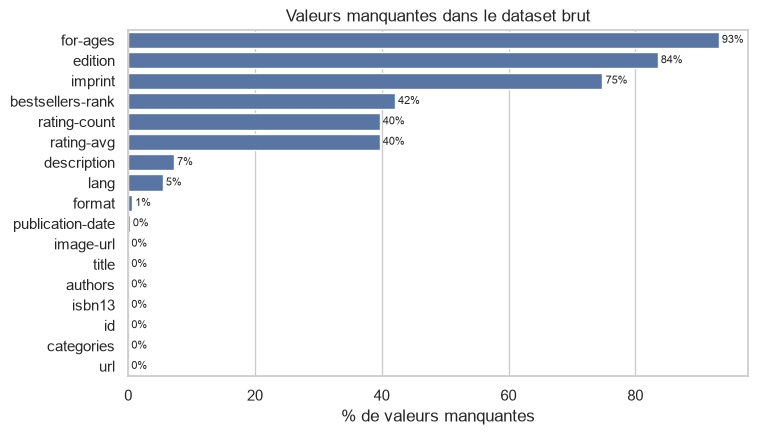

In [4]:
# Taux de valeurs manquantes par colonne : guide le choix des attributs exploitables
missing = raw.isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=missing.values * 100, y=missing.index, ax=ax, color="#4C72B0")
ax.set_xlabel("% de valeurs manquantes"); ax.set_ylabel("")
ax.set_title("Valeurs manquantes dans le dataset brut")
for i, v in enumerate(missing.values):
    ax.text(v * 100 + 0.5, i, f"{v:.0%}", va="center", fontsize=8)
save_fig(fig, "missing_values"); plt.show()

**Lecture :**
- `description` ne manque que pour 7 % des livres : c'est **la** colonne clé pour l'analyse sémantique, et elle est bien remplie.
- `for-ages` manque à **93 %** : on ne peut pas s'appuyer uniquement dessus pour le public visé, il faudra le **déduire des catégories** (section 6).
- `rating-avg` / `rating-count` (notes **Goodreads**) manquent à 40 % : ces livres sont peu connus. On s'en servira comme filtre de notoriété et pour le score de popularité.
- `edition`, `imprint` sont trop lacunaires pour être utiles.

## 3. Exploration du brut : langue, format, descriptions, notes

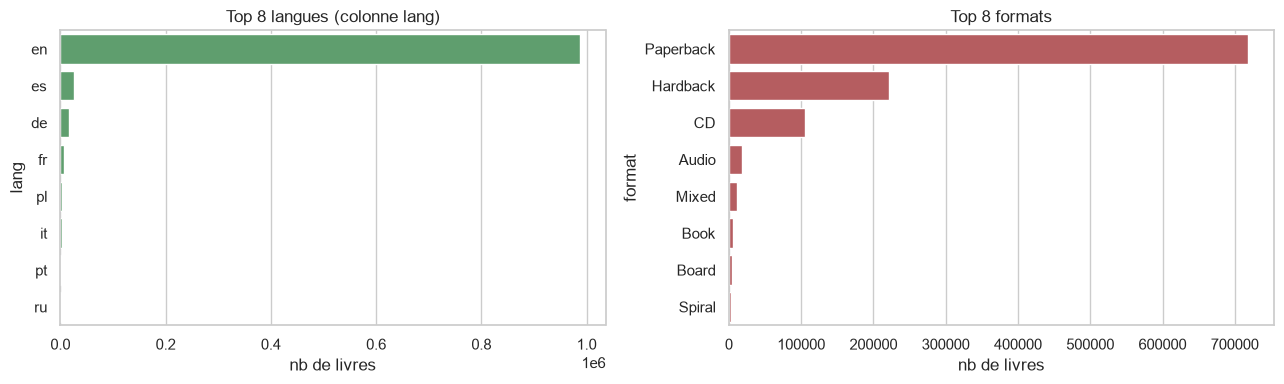

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Langues : on ne garde que l'anglais (modèle SBERT anglais + interface en anglais)
lang = raw["lang"].value_counts().head(8)
sns.barplot(x=lang.values, y=lang.index, ax=axes[0], color="#55A868")
axes[0].set_title("Top 8 langues (colonne lang)"); axes[0].set_xlabel("nb de livres")

# Formats : la colonne contient un ID -> on le traduit avec formats.csv
formats = dl.load_lookup(config.RAW_FORMATS, "format_id", "format_name")
fmt = pd.to_numeric(raw["format"], errors="coerce").map(formats).value_counts().head(8)
sns.barplot(x=fmt.values, y=fmt.index, ax=axes[1], color="#C44E52")
axes[1].set_title("Top 8 formats"); axes[1].set_xlabel("nb de livres")
plt.tight_layout(); save_fig(fig, "lang_format"); plt.show()

89 % des livres sont en anglais. Côté formats, on trouve **≈ 105 000 CD audio** et des calendriers, cartes, jeux, etc.
On ne garde que **Paperback** et **Hardback** : ce sont des livres à lire, et leurs descriptions décrivent un contenu narratif.

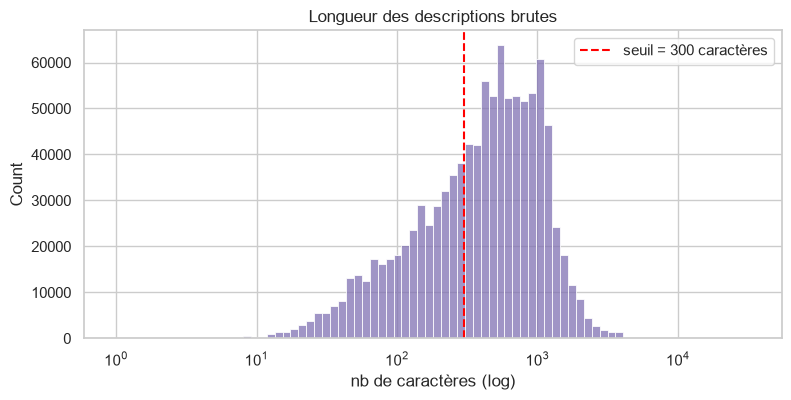

count    1029296.0
mean         561.0
std          490.0
min            1.0
25%          189.0
50%          441.0
75%          813.0
max        32709.0
Name: description, dtype: float64


In [6]:
# Distribution de la longueur des descriptions (en caractères, échelle log)
desc_len = raw["description"].dropna().str.len()
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(desc_len, bins=80, log_scale=True, ax=ax, color="#8172B3")
ax.axvline(config.MIN_DESC_CHARS, color="red", ls="--", label=f"seuil = {config.MIN_DESC_CHARS} caractères")
ax.set_title("Longueur des descriptions brutes"); ax.set_xlabel("nb de caractères (log)"); ax.legend()
save_fig(fig, "raw_description_length"); plt.show()
print(desc_len.describe().round(0))

### Les descriptions « passe-partout » : un piège pour l'analyse sémantique

En comptant les descriptions **identiques** entre livres, on découvre des textes génériques répétés des milliers de fois.
Ce sont des réimpressions automatiques du domaine public (« facsimile reprint », « Print on Demand »…) ou des carnets vendus comme livres.
Ils ne disent **rien** du contenu : tous ces livres auraient le même embedding, et une requête utilisateur pourrait leur être
« similaire » par hasard. On les détecte par motifs regex (`BOILERPLATE_PATTERNS`) et on les supprime.

In [7]:
dup = raw.loc[raw["lang"] == "en", "description"].dropna().value_counts()
print(f"{(dup >= 3).sum():,} textes répétés ≥ 3 fois, qui couvrent {dup[dup >= 3].sum():,} livres\n")
top_dup = dup.head(6).rename("nb_livres").reset_index().rename(columns={"description": "texte (début)"})
top_dup["texte (début)"] = top_dup["texte (début)"].str[:110] + "…"
top_dup

12,485 textes répétés ≥ 3 fois, qui couvrent 141,070 livres



,texte (début),nb_livres
0,"This book is a facsimile reprint and may contain imperfections such as marks, notations, marginalia and flawed…",16634
1,"This scarce antiquarian book is a facsimile reprint of the original. Due to its age, it may contain imperfecti…",5843
2,"This work has been selected by scholars as being culturally important, and is part of the knowledge base of ci…",4575
3,"This is a Print on Demand title. This book may have occasional imperfections such as missing or blurred pages,…",4549
4,This work has been selected by scholars as being culturally important and is part of the knowledge base of civ…,2394
5,"This work has been selected by scholars as being culturally important, and is part of the knowledge base of ci…",2114


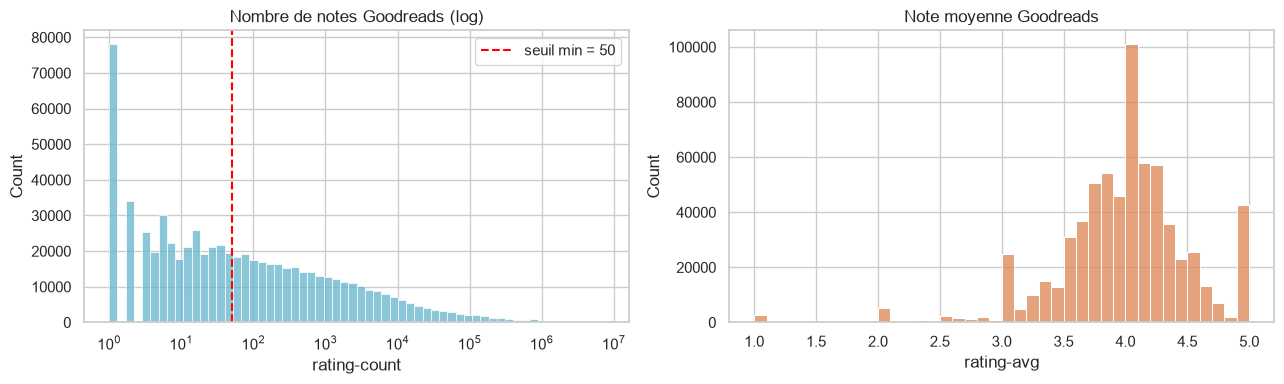

Médiane du nb de notes : 39 | max : 7,377,337


In [8]:
# Notes Goodreads : distribution très asymétrique (quelques best-sellers à plusieurs millions de notes)
rc = pd.to_numeric(raw["rating-count"], errors="coerce").dropna()
ra = pd.to_numeric(raw["rating-avg"], errors="coerce").dropna()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(rc, bins=60, log_scale=True, ax=axes[0], color="#64B5CD")
axes[0].axvline(config.MIN_RATING_COUNT, color="red", ls="--", label=f"seuil min = {config.MIN_RATING_COUNT}")
axes[0].set_title("Nombre de notes Goodreads (log)"); axes[0].legend()
sns.histplot(ra, bins=40, ax=axes[1], color="#DD8452")
axes[1].set_title("Note moyenne Goodreads")
plt.tight_layout(); save_fig(fig, "raw_ratings"); plt.show()
print("Médiane du nb de notes :", int(rc.median()), "| max :", f"{int(rc.max()):,}")

## 4. Nettoyage du texte des descriptions

### 4.1 Nettoyage minimal (`clean_description`)
Entités HTML (`&amp;` → `&`), balises résiduelles, URLs, normalisation Unicode (NFKC), espaces multiples.

**Ce qu'on ne fait volontairement PAS ici :** minuscules, suppression des stopwords, lemmatisation.
Les modèles contextuels (BERT/SBERT) ont été entraînés sur du texte naturel. Le sens de *« not a happy ending »* dépend de *not*,
et retirer les stopwords dégraderait l'embedding. Ce preprocessing « classique » est réservé aux baselines TF-IDF / GloVe (P3).

### 4.2 Retrait du texte marketing (`strip_marketing`)
≈ 7 % des descriptions commencent par des **citations de presse** (*"A chilling thriller" --Booklist*) ou des **bandeaux**
(*INSTANT #1 NEW YORK TIMES BESTSELLER*). Ces phrases parlent du **succès** du livre, pas de son **contenu**. Elles
rapprocheraient artificiellement tous les best-sellers entre eux dans l'espace d'embedding. On les retire avec des regex :
citations suivies d'une attribution `--Nom`, citations entre parenthèses, bandeaux en MAJUSCULES contenant un argument de vente.
La version avec nettoyage minimal seulement est conservée dans la colonne `description_raw` (traçabilité).

In [9]:
examples = [
    'THE INSTANT NEW YORK TIMES BESTSELLING DEBUT PSYCHOLOGICAL THRILLER YOU CAN\'T MISS! The perfect marriage? Or the perfect lie? '
    '"A hair-raising debut, both unsettling and addictive." --Mary Kubica, New York Times bestselling author of The Good Girl '
    '"This is one readers won\'t be able to put down." --Booklist (starred review) Jack and Grace seem like the perfect couple.',
    'A daring new departure from the creator of The Vampire Chronicles ("unrelentingly erotic... unforgettable"--The Washington Post). '
    'A whole new world&mdash;modern, sleek, high-tech.<br/>Visit www.example.com',
]
for e in examples:
    print("AVANT :", e, "\nAPRÈS:", dl.strip_marketing(dl.clean_description(e)), "\n")

AVANT : THE INSTANT NEW YORK TIMES BESTSELLING DEBUT PSYCHOLOGICAL THRILLER YOU CAN'T MISS! The perfect marriage? Or the perfect lie? "A hair-raising debut, both unsettling and addictive." --Mary Kubica, New York Times bestselling author of The Good Girl "This is one readers won't be able to put down." --Booklist (starred review) Jack and Grace seem like the perfect couple. 
APRÈS: The perfect marriage? Or the perfect lie? Jack and Grace seem like the perfect couple. 

AVANT : A daring new departure from the creator of The Vampire Chronicles ("unrelentingly erotic... unforgettable"--The Washington Post). A whole new world&mdash;modern, sleek, high-tech.<br/>Visit www.example.com 
APRÈS: A daring new departure from the creator of The Vampire Chronicles. A whole new world—modern, sleek, high-tech. 



## 5. Catégories : ne garder que la « lecture loisir »

Le dataset utilise la nomenclature des libraires (≈ 2 900 catégories) : on y trouve aussi bien *Contemporary Fiction* que
*Accounting Software* ou *Diets & Dieting*. Pour un système qui recommande selon des **préférences littéraires**, on classe chaque
catégorie en 4 groupes avec des règles regex **transparentes** (`classify_category`) :

| Groupe | Exemples | Décision |
|---|---|---|
| `fiction` | Contemporary Fiction, Fantasy, Manga, Poetry, Children's Fiction | **garde** |
| `nonfiction` | Memoirs, History, True Crime, Popular Science, Philosophy | **garde** (lecture narrative) |
| `excluded` | Cookery, Computing, Teaching Resources, Dictionaries, Medicine | exclut |
| `neutral` | Literary Studies, Children's Books… | ne compte pas |

**Règle de décision par livre :** au moins 1 catégorie « loisir », et au moins autant de catégories loisir que de catégories exclues.
Le test d'exclusion est fait **avant** celui de fiction, et les faux positifs de fiction sont écartés (*True Crime*, *Criminology*, *Teenagers: Advice For Parents*).

In [10]:
cat_names = dl.load_lookup(config.RAW_CATEGORIES, "category_id", "category_name")
classes = pd.Series({n: dl.classify_category(n) for n in set(cat_names.values())}, name="classe")
print(classes.value_counts(), "\n")
# Quelques exemples de chaque classe pour vérifier les règles à l'œil
for c in ["fiction", "nonfiction", "excluded", "neutral"]:
    print(f"{c:<11}:", classes[classes == c].sample(8, random_state=1).index.tolist())

classe
neutral       1351
excluded       735
nonfiction     393
fiction        106
Name: count, dtype: int64 

fiction    : ['Science Fiction', 'Fiction Companions', 'Sports Stories', 'Adventure Holidays', 'True Story Books', 'Jokes & Humour', 'Romance Books', 'Classic Books & Novels']
nonfiction : ['Gender Studies, Gender Groups', 'Family Break-Up', '20th Century & Contemporary Classical Music', 'Biography: Sport', 'Television & Film', 'Ancient Religions & Mythologies', 'Analytical Philosophy & Logical Positivism', 'Religious Buildings']
excluded   : ['Veterinary Dentistry', 'Antiques & Collectables: Books, Manuscripts, Ephemera & Printed Matter', 'Medicolegal Issues', 'Relational Databases', 'Computer Certification: Cisco', 'Medicine', 'Diving & Hyperbaric Medicine', 'Crafts & Hobbies']
neutral    : ['Koran', 'Other Nonconformist & Evangelical Churches', 'Hospital Infections', 'Microsoft Word', 'Addiction & Therapy', 'Working Patterns & Practices', 'Literary Theory', 'Handheld Operat

## 6. Public visé : Children / Young Adult / Adult

Le questionnaire demande le public visé : il faut cette information pour **filtrer**. Or `for-ages` n'est renseigné que pour 7 % des livres.
Règle `infer_audience` :
1. si `for-ages` existe, on l'utilise (âge min < 12 → *Children*, 12-17 → *Young Adult*, ≥ 18 → *Adult*) ;
2. sinon on regarde les catégories : *Teenage / Young Adult* → *Young Adult* ; *Children's / for Kids / Picture Books* → *Children* ;
3. sinon *Adult*.

In [11]:
tests = [("9-12", []), ("12-17", []), (None, ["Romance Books for Teenagers"]),
         (None, ["Fantasy Books for Kids", "Adventure Books"]), (None, ["Crime Fiction"])]
for ages, cats in tests:
    print(f"for-ages={str(ages):<6} catégories={cats!s:<48} -> {dl.infer_audience(ages, cats)}")

for-ages=9-12   catégories=[]                                               -> Children
for-ages=12-17  catégories=[]                                               -> Young Adult
for-ages=None   catégories=['Romance Books for Teenagers']                  -> Young Adult
for-ages=None   catégories=['Fantasy Books for Kids', 'Adventure Books']    -> Children
for-ages=None   catégories=['Crime Fiction']                                -> Adult


## 7. Pipeline complet de construction du catalogue

`build_catalogue()` enchaîne toutes les étapes et **logue le nombre de livres restant après chacune**.
Les étapes non encore présentées :

- **Seuil de notoriété** `rating_count ≥ 50` : moins de notes = livre confidentiel ou métadonnées pauvres.
- **Coffrets / lots** (*Box Set*, *Bundle*, *Books 1-3*) : retirés, car un coffret n'est pas *une* expérience de lecture et sa description mélange plusieurs intrigues.
- **Fusion des éditions** (section 8) : une seule ligne par œuvre.
- **Descriptions partagées** restantes : retirées (textes génériques d'éditeur).
- **Plafond de 8 livres par auteur** : sans lui, James Patterson, Stephen King ou une série de manga occuperaient des centaines de places, ce qui réduirait la diversité des recommandations. L'« auteur principal » est l'auteur de la liste le plus fréquent dans le corpus, pour ne pas compter l'illustrateur ou le traducteur.
- **Vérification de la langue** de la description (`langdetect`, graine fixée) : `lang` décrit le livre, mais certaines descriptions sont dans une autre langue.
- **Sélection finale** : les 12 000 œuvres les plus notées.

In [12]:
catalogue, report, cat_stats = dl.build_catalogue(raw=raw)

0. Raw dataset                                 1,109,383  all rows of dataset.csv


1. lang == 'en'                                  986,575  English SBERT model + English UI


2. title & description not null                  952,244  nothing to embed otherwise


3. format in Paperback/Hardback                  832,881  drop audio CDs, calendars, toys...


4. drop boilerplate descriptions                 495,766  facsimile reprints, print-on-demand, notebooks


5. clean description >= 300 chars                494,725  enough content (after removing press quotes) for an embedding
6. rating_count >= 50                            134,946  known books with reliable ratings


... (2 outputs left out)

9. drop box sets / bundles                       110,461  a box set is not a single reading experience


10. merge editions of the same work               96,040  same title+author, or same Goodreads ratings + similar title/author
11. drop shared descriptions                      93,991  generic publisher texts


12. max 8 books per author                        80,915  avoid catalogue saturation by prolific authors / manga series
13. top 13,799 candidates by rating_count         13,799  well-known books: richer descriptions, recognisable in the demo


14. description really in English                 13,711  langdetect (seed fixed)
15. final catalogue (top 12,000)                  12,000  target size reached


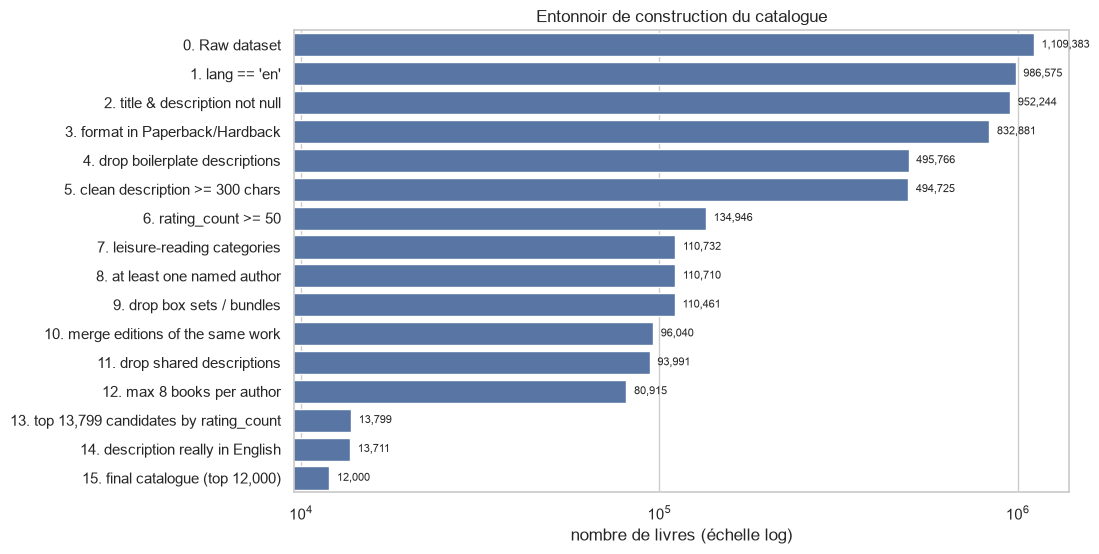

,step,rows,comment
0,0. Raw dataset,1109383,all rows of dataset.csv
1,1. lang == 'en',986575,English SBERT model + English UI
2,2. title & description not null,952244,nothing to embed otherwise
3,3. format in Paperback/Hardback,832881,"drop audio CDs, calendars, toys..."
4,4. drop boilerplate descriptions,495766,"facsimile reprints, print-on-demand, notebooks"
5,5. clean description >= 300 chars,494725,enough content (after removing press quotes) for an embedding
6,6. rating_count >= 50,134946,known books with reliable ratings
7,7. leisure-reading categories,110732,"fiction + narrative non-fiction, no textbooks/cookery/IT..."
8,8. at least one named author,110710,needed for display & dedup
9,9. drop box sets / bundles,110461,a box set is not a single reading experience


In [13]:
# Entonnoir de filtrage (figure pour le rapport)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=report, x="rows", y="step", ax=ax, color="#4C72B0")
ax.set_xscale("log"); ax.set_xlabel("nombre de livres (échelle log)"); ax.set_ylabel("")
ax.set_title("Entonnoir de construction du catalogue")
for i, v in enumerate(report["rows"]):
    ax.text(v * 1.05, i, f"{v:,}", va="center", fontsize=8)
save_fig(fig, "filtering_funnel"); plt.show()
report

### Pourquoi 12 000 livres, sélectionnés par popularité ?

Le sujet recommande **au minimum 60 livres**. Nous en gardons 12 000 pour 4 raisons :
1. **Couverture** : assez de livres pour que chaque profil (fantasy jeunesse, essai philosophique, romance historique…) ait de bons candidats.
2. **Coût** : 12 000 embeddings MiniLM se calculent en quelques minutes sur CPU, et la recherche par produit matriciel reste instantanée dans l'app.
3. **Qualité** : les livres très lus ont des descriptions éditoriales plus riches, et leurs notes sont fiables.
4. **Démo et évaluation** : des livres connus permettent de juger à l'œil si une recommandation est pertinente, et l'utilisateur peut citer un livre ou un auteur qu'il aime.

Contrepartie assumée (à discuter dans le rapport) : un **biais vers les livres populaires**. Il est en partie compensé par le plafond par auteur
et par le Likert « best-sellers ↔ pépites » du questionnaire, qui module le poids de la popularité dans le score (P4).

In [14]:
# Combien d'œuvres resteraient selon le seuil de notoriété ? (sur le vivier avant la sélection finale)
print("Plus petit nombre de notes dans le catalogue final :", f"{catalogue['rating_count'].min():,}")
print("Nombre de notes médian :", f"{int(catalogue['rating_count'].median()):,}")

Plus petit nombre de notes dans le catalogue final : 5,189
Nombre de notes médian : 14,163


## 8. Focus : la fusion des éditions multiples

Le dataset liste des **éditions**, pas des œuvres : *Pride and Prejudice* y apparaît des dizaines de fois (Penguin, Wordsworth, gros caractères…).
Sans fusion, une requête « Regency romance » renverrait 3 fois le même roman dans le top 3.

Deux difficultés :
- les auteurs ont des IDs différents selon l'édition (*J.K. Rowling*, *J. K. Rowling*, *J K Rowling*). On utilise une **clé normalisée** (`jkrowling`) ;
- les titres varient (*Philosopher's Stone* / *Sorcerer's Stone*, *Dune : Deluxe Edition*).

**Algorithme (`dedup_editions`, union-find)** : deux lignes sont la même œuvre si
- **(a)** même titre normalisé (sans mentions d'édition) **et** au moins un auteur en commun ; **ou**
- **(b)** notes Goodreads quasi identiques (Goodreads agrège les notes **par œuvre** : nombre de notes à ±2 %, moyenne à ±0,05) **et** titres proches (Jaccard des mots significatifs ≥ 0,5, ou un titre inclus dans l'autre).

Les liens sont regroupés de façon transitive (union-find). Dans chaque groupe, on garde l'édition **standard** la plus notée.

> **Itération documentée :** une première version acceptait « même auteur » sans titre proche dans la règle (b).
> L'inspection a révélé des fusions abusives (deux romans différents de Lee Child avec ±2 % de notes d'écart). La règle actuelle exige toujours un titre proche :
> les groupes suspects (titres sans aucun mot commun) sont passés de 1 606 à 23 sur ≈ 69 000 groupes, et ces 23 cas sont essentiellement de vraies traductions (*Inferno* / *The Divine Comedy : Inferno*).

In [15]:
# Démonstration sur toutes les éditions anglaises de Harry Potter tome 1
hp = raw[raw["title"].str.contains("Harry Potter and the (?:Philosopher|Sorcerer)", na=False, regex=True)
         & (raw["lang"] == "en")].copy()
authors_map = dl.load_lookup(config.RAW_AUTHORS, "author_id", "author_name")
hp["rating_count"] = pd.to_numeric(hp["rating-count"], errors="coerce")
hp["rating_avg"] = pd.to_numeric(hp["rating-avg"], errors="coerce")
hp = hp[hp["rating_count"] >= 1000]
hp["authors_list"] = hp["authors"].map(dl.parse_id_list).map(lambda ids: [authors_map[i] for i in ids if authors_map.get(i)])
hp["author_keys"] = hp["authors_list"].map(lambda l: [dl.author_key(a) for a in l])
hp["title"] = hp["title"].map(dl.clean_title)
hp["description"] = hp["description"].fillna("")
groups = dl.dedup_editions(hp, return_groups=True)
print(f"{len(hp)} éditions -> {groups['work_id'].nunique()} œuvre(s)")
groups[["title", "authors_list", "rating_count", "rating_avg", "is_special_edition", "work_id"]].head(12)

25 éditions -> 1 œuvre(s)


,title,authors_list,rating_count,rating_avg,is_special_edition,work_id
18,Harry Potter and the Sorcerer's Stone,[J. K. Rowling],7363346.0,4.48,False,0
9,Harry Potter and the Philosopher's Stone,[J.K. Rowling],7363346.0,4.48,False,0
11,Harry Potter and the Philosopher's Stone,[J.K. Rowling],7363346.0,4.48,False,0
12,Harry Potter and the Philosopher's Stone,[J.K. Rowling],7363346.0,4.48,False,0
15,Harry Potter and the Philosopher's Stone (Irish),[J.K. Rowling],7363346.0,4.48,False,0
5,Harry Potter and the Philosopher's Stone,[J. K. Rowling],7343357.0,4.48,False,0
8,Harry Potter and the Philosopher's Stone,[J.K. Rowling],7343357.0,4.48,False,0
4,Harry Potter and the Philosopher's Stone,"[Stephen Fry, J. K. Rowling]",7343357.0,4.48,False,0
0,Harry Potter and the Sorcerer's Stone,"[Jim Dale, J K Rowling]",7248094.0,4.48,False,0
3,Harry Potter and the Sorcerer's Stone,"[J K Rowling, MinaLima Design]",7248094.0,4.48,False,0


In [16]:
# Les œuvres les plus « fusionnées » du catalogue final
catalogue.sort_values("n_editions", ascending=False)[["title", "main_author", "n_editions"]].head(10)

,title,main_author,n_editions
33,Romeo and Juliet,William Shakespeare,101
338,The Art of War,Sun Tzu,72
963,Tao Te Ching : The Way of Nature and Its Virtues,Laozi,67
2002,Bhagavad Gita,B S Miller,47
631,Around The World In Eighty Days,Jules Verne,38
66,Frankenstein,Mary Shelley,34
155,Macbeth,William Shakespeare,32
8,Pride and Prejudice,Jane Austin,31
184,A Christmas Carol,Charles Dickens,30
4951,The Analects of Confucius,Confucius,26


## 9. Analyse exploratoire du catalogue final

In [17]:
print(f"{len(catalogue):,} livres | {catalogue['main_author'].nunique():,} auteurs principaux distincts")
ct = pd.crosstab(catalogue["domain"], catalogue["audience"], margins=True)
ct

12,000 livres | 5,994 auteurs principaux distincts


audience,Adult,Children,Young Adult,All
domain,,,,
Fiction,6906,1332,1105,9343
Non-fiction,2415,122,120,2657
All,9321,1454,1225,12000


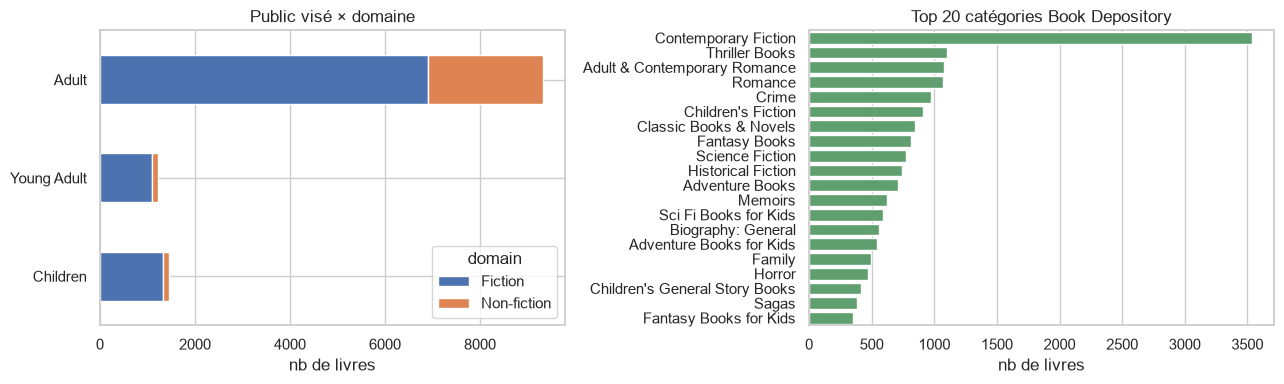

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
# Répartition domaine × public
pd.crosstab(catalogue["audience"], catalogue["domain"]).loc[list(config.AUDIENCES)].plot(
    kind="barh", stacked=True, ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Public visé × domaine"); axes[0].set_xlabel("nb de livres"); axes[0].set_ylabel("")
# Top catégories (après fusion des doublons de libellés type "Thrillers" / "Thriller Books")
top_cats = cat_stats.drop_duplicates("n_books").head(20)
sns.barplot(data=top_cats, x="n_books", y="category", ax=axes[1], color="#55A868")
axes[1].set_title("Top 20 catégories Book Depository"); axes[1].set_xlabel("nb de livres"); axes[1].set_ylabel("")
plt.tight_layout(); save_fig(fig, "catalogue_audience_categories"); plt.show()

Le catalogue est majoritairement de la fiction adulte, avec une part significative de **jeunesse / Young Adult (≈ 22 %)** et de **non-fiction narrative (≈ 22 %)**.
Tous les profils du questionnaire ont donc des candidats. Les catégories sont nombreuses et redondantes (*Thrillers* / *Thriller Books*) :
c'est pourquoi P2 les regroupe en ≈ 15 **macro-genres sémantiques** (fichier `category_stats.csv` fourni).

### Longueur des descriptions en **tokens** : impact sur le choix du modèle

Les modèles SBERT ont une longueur maximale : **256 tokens** pour `all-MiniLM-L6-v2`, 384 pour `all-mpnet-base-v2`. Au-delà, le texte est **tronqué**.
On mesure la longueur réelle de `embed_text` (titre + description) avec le **vrai tokenizer** du modèle, pour savoir quelle part des livres est entièrement « lue » par le modèle.

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


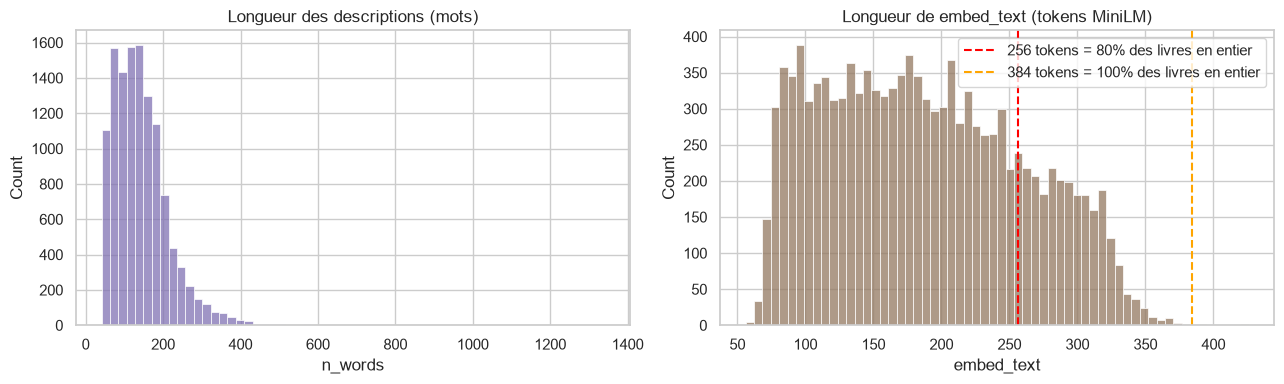

count    12000.0
mean       187.0
std         72.0
min         56.0
25%        126.0
50%        181.0
75%        241.0
max        426.0
Name: embed_text, dtype: float64


In [19]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(config.EMBEDDING_MODEL)
n_tokens = catalogue["embed_text"].map(lambda t: len(tok(t, add_special_tokens=True)["input_ids"]))
catalogue["n_tokens"] = n_tokens   # colonne temporaire pour l'analyse (non exportée)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(catalogue["n_words"], bins=60, ax=axes[0], color="#8172B3")
axes[0].set_title("Longueur des descriptions (mots)")
sns.histplot(n_tokens, bins=60, ax=axes[1], color="#937860")
for lim, c in [(256, "red"), (384, "orange")]:
    axes[1].axvline(lim, color=c, ls="--", label=f"{lim} tokens = {(n_tokens <= lim).mean():.0%} des livres en entier")
axes[1].set_title("Longueur de embed_text (tokens MiniLM)"); axes[1].legend()
plt.tight_layout(); save_fig(fig, "description_tokens"); plt.show()
print(n_tokens.describe().round(0))

La troncature à ≈ 1 500 caractères de `embed_text` (fin de phrase propre) garde **l'essentiel du résumé** : la grande majorité des livres tient dans
les 256 tokens de MiniLM, et le début d'une description éditoriale (le « pitch ») est la partie la plus informative.
La personne 3 peut comparer troncature et moyenne de morceaux (*chunking*) pour les descriptions les plus longues.

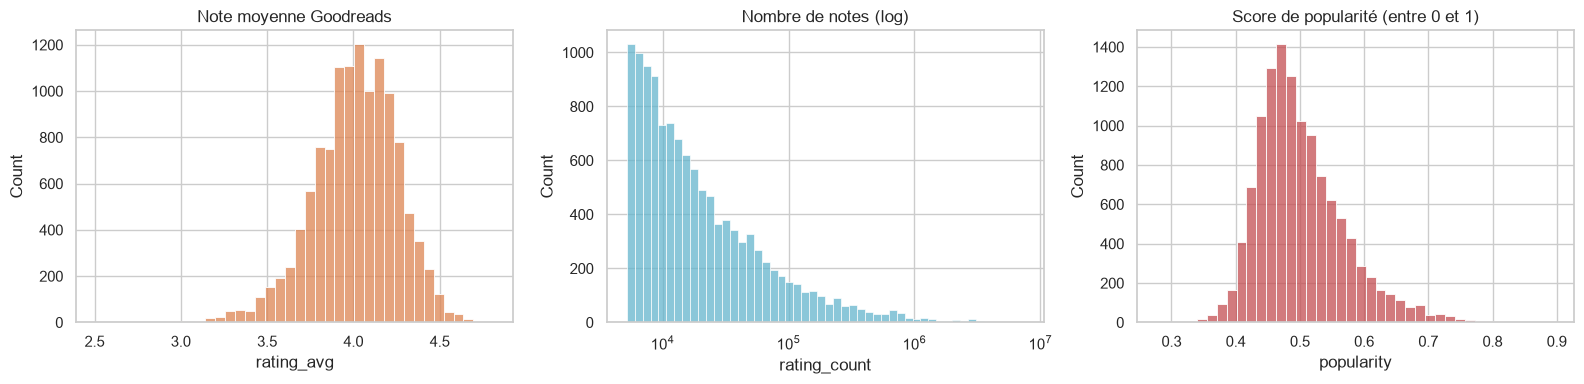

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(catalogue["rating_avg"], bins=40, ax=axes[0], color="#DD8452")
axes[0].set_title("Note moyenne Goodreads")
sns.histplot(catalogue["rating_count"], bins=50, log_scale=True, ax=axes[1], color="#64B5CD")
axes[1].set_title("Nombre de notes (log)")
sns.histplot(catalogue["popularity"], bins=40, ax=axes[2], color="#C44E52")
axes[2].set_title("Score de popularité (entre 0 et 1)")
plt.tight_layout(); save_fig(fig, "catalogue_ratings_popularity"); plt.show()

**Score de popularité** (utilisé dans la formule finale de P4) :

$$\text{Pop}(j) = \frac{\text{rating\_avg}_j}{5} \times \frac{\log(1+\text{rating\_count}_j)}{\log(1+\max_k \text{rating\_count}_k)}$$

Le **logarithme** évite qu'*Harry Potter* (7 M de notes) écrase tout : passer de 10 000 à 100 000 notes compte autant que de 100 000 à 1 M.
Le facteur `rating_avg/5` favorise les livres appréciés, pas seulement les livres connus.

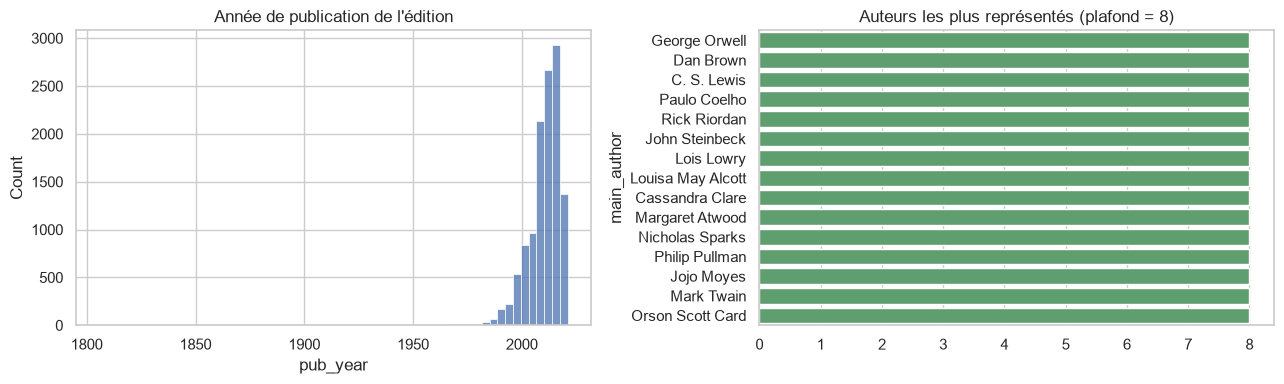

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(catalogue["pub_year"].dropna(), bins=60, ax=axes[0], color="#4C72B0")
axes[0].set_title("Année de publication de l'édition")
top_auth = catalogue["main_author"].value_counts().head(15)
sns.barplot(x=top_auth.values, y=top_auth.index, ax=axes[1], color="#55A868")
axes[1].set_title("Auteurs les plus représentés (plafond = 8)")
plt.tight_layout(); save_fig(fig, "catalogue_years_authors"); plt.show()

⚠️ `pub_year` est l'année de publication **de l'édition** (souvent une réédition récente) et **pas l'époque du récit** : *Pride and Prejudice* y apparaît en 2000+.
L'époque et l'ambiance du récit (*Victorian era*, *World War II*…) seront donc déterminées **sémantiquement** à partir de la description (bloc *Atmosphere*, P2).
`pub_year` ne sert que de filtre optionnel. Les années aberrantes (ex. 2099, date factice « à paraître ») sont remplacées par des valeurs manquantes.

In [22]:
# Aperçu qualitatif : 5 livres au hasard (vérification à l'œil de la qualité du texte)
for _, r in catalogue.sample(5, random_state=3).iterrows():
    print(f"■ {r.title} | {r.main_author} | {r.audience} · {r.domain} | {r.categories[:3]}")
    print("  ", r.description[:300], "…\n")

■ Goodbye to Berlin | Christopher Isherwood | Adult · Fiction | ['Contemporary Fiction', 'Classic Books & Novels']
   First published in 1934, Goodbye to Berlin has been popularized on stage and screen by Julie Harris in I Am a Camera and Liza Minelli in Cabaret. Isherwood magnificently captures 1931 Berlin: charming, with its avenues and cafes; marvelously grotesque, with its nightlife and dreamers; dangerous, wit …

■ Shacking Up | Helena Hunting | Adult · Fiction | ['Romance', 'Romance Books', 'Adult & Contemporary Romance']
   Ruby Scott is months behind on rent and can't seem to land a steady job. She has one chance to turn things around with a big audition. But instead of getting her big break, she gets sick as a dog and completely bombs it in the most humiliating fashion. All thanks to a mysterious, gorgeous guy who ki …

■ Home Again | Kristin Hannah | Adult · Fiction | ['Contemporary Fiction', 'Romance', 'Romance Books']
   Madelaine Hillyard is a brilliant cardiologist at the

## 10. Export et schéma

- `books_clean.parquet` : catalogue complet.
- `books_sample.parquet` : **500 livres stratifiés** (domaine × public), avec les colonnes d'enrichissement de P2 (`genres`, `themes`, `styles`, `atmospheres`, `keywords`, `label_scores`) **déjà présentes mais vides**. Toute l'équipe peut coder contre le schéma final sans attendre.
- Parquet plutôt que CSV : types conservés (listes, entiers nullables), lecture 10× plus rapide, fichier ≈ 5× plus petit.

In [23]:
catalogue = catalogue.drop(columns=["n_tokens"])
sample = dl.make_sample(catalogue)
dl.save_parquet(catalogue, config.BOOKS_CLEAN)
dl.save_parquet(sample, config.BOOKS_SAMPLE)
report.to_csv(config.FILTERING_REPORT, index=False)
cat_stats.to_csv(config.CATEGORY_STATS, index=False)
for p in [config.BOOKS_CLEAN, config.BOOKS_SAMPLE, config.FILTERING_REPORT, config.CATEGORY_STATS]:
    print(f"{p.relative_to(ROOT)!s:<45} {p.stat().st_size / 1e6:6.2f} Mo")
print("\nÉchantillon par strate :\n", pd.crosstab(sample["domain"], sample["audience"]))

data/processed/books_clean.parquet             15.53 Mo
data/processed/books_sample.parquet             0.68 Mo
data/reference/filtering_report.csv             0.00 Mo
data/reference/category_stats.csv               0.04 Mo

Échantillon par strate :
 audience     Adult  Children  Young Adult
domain                                   
Fiction        286        56           46
Non-fiction    102         5            5


In [24]:
# Dictionnaire des colonnes (repris dans le rapport)
schema = pd.DataFrame({
    "colonne": catalogue.columns,
    "type": [str(t) for t in catalogue.dtypes],
    "exemple": [str(catalogue.iloc[0][c])[:60] for c in catalogue.columns],
})
schema

,colonne,type,exemple
0,book_id,str,9780590353427
1,title,str,Harry Potter and the Sorcerer's Stone
2,authors,object,['J. K. Rowling']
3,authors_str,str,J. K. Rowling
4,main_author,str,J. K. Rowling
5,categories,object,"[""Children's General Story Books"", 'Sci Fi Books for Kids',"
6,description,str,"Harry Potter has never been the star of a Quidditch team, sc"
7,description_raw,str,"Harry Potter has never been the star of a Quidditch team, sc"
8,pub_year,Int64,1999
9,rating_avg,float64,4.48


## 11. Utilitaires fournis au reste de l'équipe

Fonctions de `src/data_loader.py` utilisées par le moteur de recommandation (P4) et l'app (P5) :
- `load_books()` : charge le meilleur catalogue disponible (enrichi > propre > échantillon) et reconvertit les colonnes liste et JSON ;
- `find_author()` / `get_books_by_author()` : matching **flou** (rapidfuzz) de l'auteur favori saisi dans le questionnaire, tolérant aux fautes de frappe ;
- `apply_constraints()` : masque booléen des **filtres durs** du questionnaire (public, format, période de publication, auteurs exclus, fiction/non-fiction).

In [25]:
books = dl.load_books(config.BOOKS_CLEAN)
print("'stephen kng'   ->", dl.find_author(books, "stephen kng"))
print("'tolkien'       ->", dl.find_author(books, "tolkien"))
print("'jk rowling'    ->", dl.find_author(books, "jk rowling"))
print(dl.get_books_by_author(books, "agatha christie")[["title", "rating_count"]].head(5), "\n")

mask = dl.apply_constraints(books, audience="Young Adult", formats=["Paperback"],
                            excluded_authors=["Suzanne Collins"], fiction_only=True)
print(f"Young Adult + Paperback + fiction, sans Suzanne Collins : {mask.sum():,} livres")

'stephen kng'   -> Stephen King
'tolkien'       -> J R R Tolkien
'jk rowling'    -> J K Rowling
                                                                                         title  \
291                                                           The Murder on the Orient Express   
433   The Mysterious Affair at Styles : Hercule Poirot's First Case (Hercule Poirot Mysteries)   
1334                                                                 The Man in the Brown Suit   
2072                                                                   The Murder on the Links   
2402                                                                       Poirot Investigates   

      rating_count  
291         402240  
433         272385  
1334         86563  
2072         53599  
2402         46157   

Young Adult + Paperback + fiction, sans Suzanne Collins : 874 livres


## 12. Synthèse des choix et limites

| Choix | Justification |
|---|---|
| Anglais uniquement | modèle SBERT anglais, interface en anglais, 89 % du dataset |
| Paperback / Hardback | retire 105 k CD audio, calendriers, jeux : pas de contenu narratif |
| Description ≥ 300 caractères, sans texte générique ni marketing | il faut du **contenu** pour un embedding sémantique pertinent |
| `rating_count ≥ 50` puis top 12 000 par popularité | notes fiables, livres reconnaissables (démo, évaluation), coût raisonnable |
| Catégories « lecture loisir » | le système recommande selon des préférences **littéraires** |
| Fusion des éditions (union-find) | une œuvre = une ligne : pas de doublons dans le top 3 |
| 8 livres max par auteur | diversité du catalogue et des recommandations |
| Public déduit (for-ages + catégories) | for-ages manque à 93 % ; nécessaire au filtre du questionnaire |
| Preprocessing minimal | SBERT exploite le contexte complet (stopwords, négations, ponctuation) |

**Limites :**
- **Biais de popularité et anglophone** : le catalogue reflète les ventes d'un libraire en ligne britannique.
- Les descriptions restent des **textes éditoriaux** : il reste un peu de marketing (« #1 bestselling classic ») que les regex ne retirent pas entièrement.
- Le classement des catégories et la déduction du public sont faits par **règles** : quelques erreurs à la marge (ex. un roman adulte étiqueté *Children's Fiction* par le libraire).
- `pub_year` n'est pas l'époque du récit.
- La fusion des éditions fait rarement des erreurs (≈ 20 groupes douteux sur 69 000 : traductions et anthologies au titre très différent).

➡️ **Suite :** P2 enrichit ce catalogue (genres, thèmes, style, atmosphère, mots-clés → `books_enriched.parquet`), puis P3 calcule les embeddings.